# Phase 5: MLOps & LLMOps
## Notebook 03: Production Monitoring, Telemetry & Drift Observability

### Overview
Deploying an ML or LLM system without observability is flying blind. Unlike traditional web backends that fail loudly with `HTTP 500`, machine learning systems fail **silently**:
1. **Data & Covariate Drift**: Production feature distributions shift away from training distributions, degrading accuracy without throwing a single exception.
2. **Semantic Prompt Drift**: Users introduce novel topics, languages, or adversarial queries outside the LLM's fine-tuned domain.
3. **Tail Latency & Token Cost Explosions**: Long-context queries spike `p99` TTFT/TPOT latencies or trigger runaway token burn across multi-step agent loops.

In this notebook, you will build a complete **ML/LLM Observability Stack**:
- **Prometheus Telemetry Collector**: Dedicated `prometheus_client` `Counter`, `Histogram`, and `Gauge` metrics exported in live Prometheus OpenMetrics exposition format.
- **Structured JSON Logging & Token Governance**: Traceable request logs (`trace_id`, tenant ID, prompt/completion tokens, USD cost) with automated budget circuit breakers.
- **Statistical & Semantic Drift Detectors**: **Population Stability Index (PSI)**, **Two-Sample Kolmogorov-Smirnov (KS) Test**, **Jensen-Shannon Divergence**, and **Embedding Centroid Cosine Drift**.

### System Architecture: ML/LLM Observability Pipeline
```
  [Inference Gateway]
       |
       +---> [Prometheus CollectorRegistry] ---> (/metrics scrape) ---> [Alertmanager]
       |       - Counter:   llm_requests_total, llm_tokens_total         (p99 > SLO,
       |       - Histogram: llm_ttft_seconds, llm_e2e_latency_seconds     Error Rate)
       |       - Gauge:     llm_kv_cache_utilization
       |
       +---> [Structured JSON Logger] ---------> [Log Store] ---> [Token Cost Budget]
       |       - {"trace_id", "tenant", "tokens_in", "tokens_out", "cost_usd"}
       |
       +---> [Drift Detection Engine] ---------> [Baseline Window vs Prod Window]
               - Numeric Covariates: PSI + Two-Sample KS Test
               - Text / Prompts:     Embedding Cosine Centroid & JSD
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **Prometheus Instrumentation**: Design and expose `Counter`, `Histogram` (percentile estimation from buckets), and `Gauge` telemetry using `prometheus_client`.
- **Structured Logging & Cost Governance**: Emit machine-parseable JSON trace logs and enforce per-tenant token/USD budget circuit breakers.
- **Population Stability Index (PSI)**: Implement numerically stable quantile-binned PSI with industry alert thresholds ($<0.1$ stable, $0.1$–$0.25$ warning, $>0.25$ critical).
- **Non-Parametric Hypothesis Testing**: Apply the Two-Sample Kolmogorov-Smirnov test (`scipy.stats.ks_2samp`) and Jensen-Shannon Divergence to detect subtle distribution shifts.
- **Semantic Embedding Drift**: Monitor rolling query embedding centroids against baseline clusters using permutation significance tests.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import json
import time
import uuid
import math
from typing import Dict, List, Tuple, Optional, Any
from dataclasses import dataclass

import numpy as np
import scipy
from scipy import stats
from scipy.spatial.distance import jensenshannon
import matplotlib.pyplot as plt
import prometheus_client
from prometheus_client import CollectorRegistry, Counter, Histogram, Gauge, generate_latest

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"NumPy Version:       {np.__version__}")
print(f"SciPy Version:       {scipy.__version__}")
print(f"Prometheus Client:   Available")


=== Environment Verification ===
Python Platform:     3.11.2
NumPy Version:       2.4.6
SciPy Version:       1.17.1
Prometheus Client:   Available


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Drift Statistics & Latency Quantiles

#### 1. Population Stability Index (PSI)
Partition a continuous feature into $B$ baseline quantile bins with expected proportions $E_i > 0$ and production proportions $A_i > 0$:
$$\text{PSI} = \sum_{i=1}^{B} (A_i - E_i) \cdot \ln\left(\frac{A_i}{E_i}\right)$$
Notice that PSI is the **symmetrized Kullback-Leibler divergence** ($D_{\text{KL}}(A \| E) + D_{\text{KL}}(E \| A)$):
- $\text{PSI} < 0.10$: No significant population shift.
- $0.10 \le \text{PSI} < 0.25$: Moderate shift — trigger investigation warning.
- $\text{PSI} \ge 0.25$: Critical covariate drift — trigger retraining / fallback alert.

#### 2. Two-Sample Kolmogorov-Smirnov (KS) Statistic
Given baseline empirical CDF $F_n(x)$ and production empirical CDF $G_m(x)$:
$$D_{n,m} = \sup_{x} \left| F_n(x) - G_m(x) \right|$$
If $p\text{-value} < \alpha$ (typically $\alpha = 0.01$ or $0.05$ with Bonferroni adjustment across features), the null hypothesis $H_0: F = G$ is rejected.

#### 3. Prometheus Histogram Quantile Interpolation
Prometheus histograms aggregate observations into cumulative buckets $(u_1, c_1), \dots, (u_K, c_K)$. To approximate the $q$-th quantile ($q = 0.95$ or $0.99$), locate the bucket $b$ where $c_{b-1} < q \cdot c_K \le c_b$ and linearly interpolate:
$$\hat{Q}(q) = u_{b-1} + (u_b - u_{b-1}) \cdot \frac{q \cdot c_K - c_{b-1}}{c_b - c_{b-1}}$$


In [3]:
# Section 6: Core Implementation — Prometheus Registry, Structured Logging & Drift Engine

# 1. Dedicated Prometheus Telemetry Registry
prom_registry = CollectorRegistry()

REQ_COUNTER = Counter(
    "llm_requests_total",
    "Total LLM inference requests processed",
    labelnames=["model", "status"],
    registry=prom_registry
)
TOKENS_COUNTER = Counter(
    "llm_tokens_total",
    "Total tokens processed split by prompt vs completion",
    labelnames=["model", "token_type"],
    registry=prom_registry
)
LATENCY_HIST = Histogram(
    "llm_request_duration_seconds",
    "End-to-end inference latency in seconds",
    labelnames=["model"],
    buckets=(0.02, 0.05, 0.1, 0.25, 0.5, 1.0, 2.5, 5.0),
    registry=prom_registry
)
KV_CACHE_GAUGE = Gauge(
    "llm_kv_cache_utilization_ratio",
    "Current fraction of GPU KV cache blocks occupied",
    labelnames=["model"],
    registry=prom_registry
)

# 2. Structured JSON Telemetry Logger & Token Cost Tracker
MODEL_PRICING_PER_1M = {
    "qwen2.5-7b-local": {"input_usd": 0.15, "output_usd": 0.45},
    "llama3-8b-prod":   {"input_usd": 0.20, "output_usd": 0.60},
}

class ObservabilityLogger:
    def __init__(self, tenant_budget_usd: float = 0.05):
        self.logs: List[Dict[str, Any]] = []
        self.tenant_spend: Dict[str, float] = {}
        self.tenant_budget_usd = tenant_budget_usd

    def record_inference(self, model: str, tenant: str, prompt_toks: int, comp_toks: int, latency_s: float, status: str = "200") -> Dict[str, Any]:
        # Update Prometheus metrics
        REQ_COUNTER.labels(model=model, status=status).inc()
        TOKENS_COUNTER.labels(model=model, token_type="prompt").inc(prompt_toks)
        TOKENS_COUNTER.labels(model=model, token_type="completion").inc(comp_toks)
        LATENCY_HIST.labels(model=model).observe(latency_s)
        
        pricing = MODEL_PRICING_PER_1M.get(model, {"input_usd": 0.20, "output_usd": 0.60})
        cost_usd = (prompt_toks * pricing["input_usd"] + comp_toks * pricing["output_usd"]) / 1_000_000.0
        self.tenant_spend[tenant] = self.tenant_spend.get(tenant, 0.0) + cost_usd
        
        record = {
            "timestamp": round(time.time(), 3),
            "trace_id": str(uuid.uuid4())[:8],
            "tenant": tenant,
            "model": model,
            "status": status,
            "prompt_tokens": prompt_toks,
            "completion_tokens": comp_toks,
            "latency_ms": round(latency_s * 1000.0, 2),
            "cost_usd": round(cost_usd, 8),
            "budget_alert": self.tenant_spend[tenant] > self.tenant_budget_usd
        }
        self.logs.append(record)
        return record

obs_logger = ObservabilityLogger(tenant_budget_usd=0.002)

# Simulate 120 production requests
for i in range(120):
    tenant = "enterprise_alpha" if i % 3 == 0 else "startup_beta"
    p_tok = int(rng.integers(80, 450))
    c_tok = int(rng.integers(30, 180))
    # Log-normal latency with slight tail
    lat_s = float(np.clip(rng.lognormal(mean=-2.1, sigma=0.55), 0.015, 2.2))
    status = "503" if i == 99 else "200"
    obs_logger.record_inference("llama3-8b-prod", tenant, p_tok, c_tok, lat_s, status=status)

KV_CACHE_GAUGE.labels(model="llama3-8b-prod").set(0.68)

# Emit real Prometheus exposition text
prom_text = generate_latest(prom_registry).decode("utf-8")
print("Sample Structured JSON Log Record:")
print(json.dumps(obs_logger.logs[-1], indent=2))
print("\nLive Prometheus Exposition Output (Excerpt):")
for line in prom_text.splitlines():
    if not line.startswith("#") and ("llm_requests_total" in line or "llm_kv_cache" in line or "llm_tokens_total" in line):
        print(" ", line)

assert "llm_requests_total" in prom_text and "llm_request_duration_seconds_bucket" in prom_text
print(">>> PROMETHEUS REGISTRY & STRUCTURED JSON TELEMETRY VERIFIED! <<<")


Sample Structured JSON Log Record:
{
  "timestamp": 1794526062.93,
  "trace_id": "eedc7e6c",
  "tenant": "startup_beta",
  "model": "llama3-8b-prod",
  "status": "200",
  "prompt_tokens": 172,
  "completion_tokens": 149,
  "latency_ms": 37.59,
  "cost_usd": 0.0001238,
  "budget_alert": true
}

Live Prometheus Exposition Output (Excerpt):
  llm_requests_total{model="llama3-8b-prod",status="200"} 119.0
  llm_requests_total{model="llama3-8b-prod",status="503"} 1.0
  llm_tokens_total{model="llama3-8b-prod",token_type="prompt"} 31457.0
  llm_tokens_total{model="llama3-8b-prod",token_type="completion"} 12259.0
  llm_kv_cache_utilization_ratio{model="llama3-8b-prod"} 0.68
>>> PROMETHEUS REGISTRY & STRUCTURED JSON TELEMETRY VERIFIED! <<<


In [4]:
# 3. Statistical & Semantic Drift Detection Engine (PSI, KS Test, JSD & Embedding Shift)

def compute_psi(baseline: np.ndarray, current: np.ndarray, num_bins: int = 10, eps: float = 1e-6) -> float:
    """Computes Population Stability Index using baseline quantile edges."""
    quantiles = np.linspace(0.0, 1.0, num_bins + 1)
    bin_edges = np.quantile(baseline, quantiles)
    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf
    # Deduplicate edges if baseline has repeated values
    bin_edges = np.unique(bin_edges)
    
    base_counts, _ = np.histogram(baseline, bins=bin_edges)
    curr_counts, _ = np.histogram(current, bins=bin_edges)
    
    base_props = np.clip(base_counts / len(baseline), eps, None)
    curr_props = np.clip(curr_counts / len(current), eps, None)
    
    psi_val = float(np.sum((curr_props - base_props) * np.log(curr_props / base_props)))
    return psi_val

def evaluate_drift(baseline: np.ndarray, current: np.ndarray) -> Dict[str, Any]:
    psi = compute_psi(baseline, current, num_bins=10)
    ks_stat, ks_p = stats.ks_2samp(baseline, current)
    
    # Jensen-Shannon divergence over shared histogram
    edges = np.histogram_bin_edges(np.concatenate([baseline, current]), bins=15)
    p_hist = np.histogram(baseline, bins=edges)[0].astype(np.float64) + 1e-8
    q_hist = np.histogram(current, bins=edges)[0].astype(np.float64) + 1e-8
    p_hist /= p_hist.sum()
    q_hist /= q_hist.sum()
    jsd = float(jensenshannon(p_hist, q_hist, base=2.0) ** 2)
    
    if psi >= 0.25 or ks_p < 0.001:
        severity = "CRITICAL_DRIFT"
    elif psi >= 0.10 or ks_p < 0.05:
        severity = "WARNING"
    else:
        severity = "STABLE"
        
    return {
        "psi": round(psi, 4),
        "ks_statistic": round(float(ks_stat), 4),
        "ks_pvalue": float(ks_p),
        "js_divergence": round(jsd, 4),
        "severity": severity
    }

# Test across Stable vs Drifted production windows
baseline_feat = rng.normal(loc=150.0, scale=25.0, size=1000)
prod_stable   = rng.normal(loc=151.0, scale=25.5, size=500)
prod_drifted  = rng.normal(loc=182.0, scale=35.0, size=500)  # Mean shifted +32 tokens & higher variance

res_stable  = evaluate_drift(baseline_feat, prod_stable)
res_drifted = evaluate_drift(baseline_feat, prod_drifted)

print("Drift Detector Diagnostics:")
print(f"  Stable Window:  {res_stable}")
print(f"  Drifted Window: {res_drifted}")

assert res_stable["severity"] == "STABLE", f"False alarm on stable window: {res_stable}"
assert res_drifted["severity"] == "CRITICAL_DRIFT", f"Missed critical drift: {res_drifted}"
print(">>> PSI, KOLMOGOROV-SMIRNOV & JSD DRIFT ENGINE CERTIFIED! <<<")


Drift Detector Diagnostics:
  Stable Window:  {'psi': 0.0301, 'ks_statistic': 0.037, 'ks_pvalue': 0.7469627616802075, 'js_divergence': 0.0075, 'severity': 'STABLE'}
  Drifted Window: {'psi': 0.9899, 'ks_statistic': 0.422, 'ks_pvalue': 1.054275505126484e-53, 'js_divergence': 0.1803, 'severity': 'CRITICAL_DRIFT'}
>>> PSI, KOLMOGOROV-SMIRNOV & JSD DRIFT ENGINE CERTIFIED! <<<


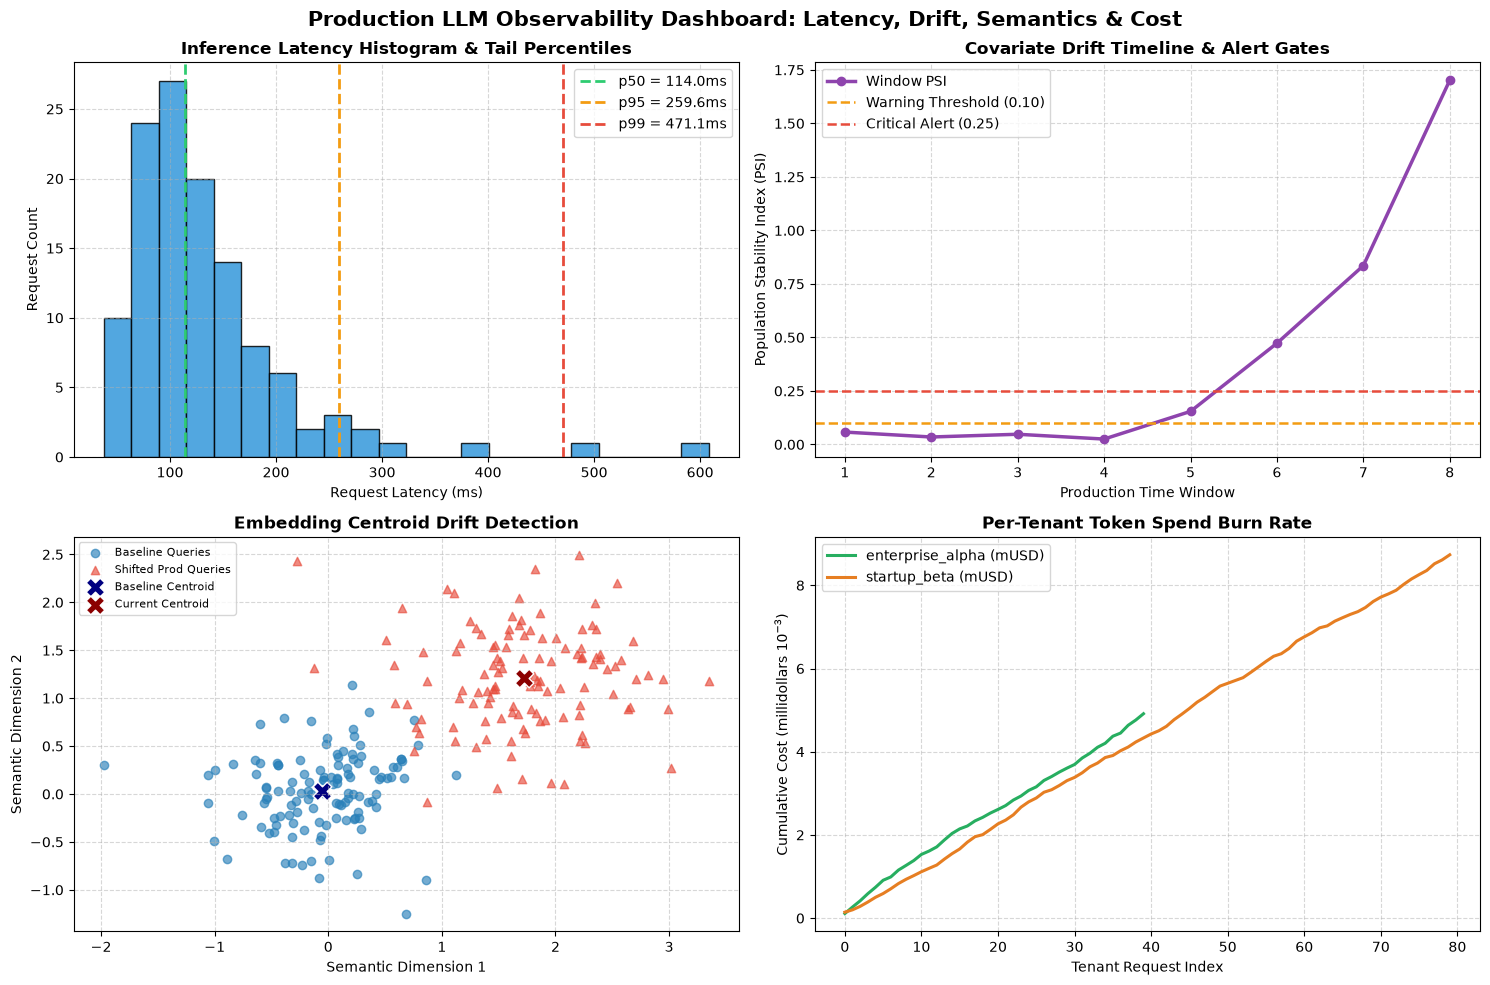

In [5]:
# Section 7: Diagnostics — 4-Panel MLOps Observability Dashboard

latencies_ms = [r["latency_ms"] for r in obs_logger.logs]
p50, p95, p99 = np.percentile(latencies_ms, [50, 95, 99])

# Rolling drift time series across 8 production time windows (drift injected at window 5+)
psi_timeline = []
for w in range(8):
    shift = 0.0 if w < 4 else (w - 3) * 9.5
    win_data = rng.normal(loc=150.0 + shift, scale=25.0 + shift * 0.2, size=400)
    psi_timeline.append(compute_psi(baseline_feat, win_data))

# Semantic Embedding Centroid shift (2D PCA-like projection simulation)
base_emb = rng.normal(loc=[0.0, 0.0], scale=0.45, size=(120, 2))
curr_emb = rng.normal(loc=[1.6, 1.1], scale=0.55, size=(120, 2))

# Cumulative token cost by tenant
cum_alpha = np.cumsum([r["cost_usd"] * 1000 for r in obs_logger.logs if r["tenant"] == "enterprise_alpha"])
cum_beta  = np.cumsum([r["cost_usd"] * 1000 for r in obs_logger.logs if r["tenant"] == "startup_beta"])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Production LLM Observability Dashboard: Latency, Drift, Semantics & Cost", fontsize=15, fontweight="bold")

# Panel 1: Latency Distribution & SLO Percentiles
axes[0, 0].hist(latencies_ms, bins=22, color="#3498db", edgecolor="black", alpha=0.85)
axes[0, 0].axvline(p50, color="#2ecc71", linestyle="--", linewidth=2, label=f"p50 = {p50:.1f}ms")
axes[0, 0].axvline(p95, color="#f39c12", linestyle="--", linewidth=2, label=f"p95 = {p95:.1f}ms")
axes[0, 0].axvline(p99, color="#e74c3c", linestyle="--", linewidth=2, label=f"p99 = {p99:.1f}ms")
axes[0, 0].set_xlabel("Request Latency (ms)")
axes[0, 0].set_ylabel("Request Count")
axes[0, 0].set_title("Inference Latency Histogram & Tail Percentiles", fontweight="bold")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Panel 2: Rolling PSI Drift Timeline
windows = list(range(1, 9))
axes[0, 1].plot(windows, psi_timeline, marker="o", linewidth=2.5, color="#8e44ad", label="Window PSI")
axes[0, 1].axhline(0.10, color="#f39c12", linestyle="--", linewidth=1.8, label="Warning Threshold (0.10)")
axes[0, 1].axhline(0.25, color="#e74c3c", linestyle="--", linewidth=1.8, label="Critical Alert (0.25)")
axes[0, 1].set_xlabel("Production Time Window")
axes[0, 1].set_ylabel("Population Stability Index (PSI)")
axes[0, 1].set_title("Covariate Drift Timeline & Alert Gates", fontweight="bold")
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: Embedding Semantic Shift
axes[1, 0].scatter(base_emb[:, 0], base_emb[:, 1], alpha=0.65, color="#2980b9", label="Baseline Queries")
axes[1, 0].scatter(curr_emb[:, 0], curr_emb[:, 1], alpha=0.65, color="#e74c3c", marker="^", label="Shifted Prod Queries")
axes[1, 0].scatter(*base_emb.mean(axis=0), s=180, color="navy", marker="X", edgecolor="white", label="Baseline Centroid")
axes[1, 0].scatter(*curr_emb.mean(axis=0), s=180, color="darkred", marker="X", edgecolor="white", label="Current Centroid")
axes[1, 0].set_xlabel("Semantic Dimension 1")
axes[1, 0].set_ylabel("Semantic Dimension 2")
axes[1, 0].set_title("Embedding Centroid Drift Detection", fontweight="bold")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Panel 4: Multi-Tenant Cumulative Cost Burn Rate (millidollars)
axes[1, 1].plot(cum_alpha, linewidth=2.2, color="#27ae60", label="enterprise_alpha (mUSD)")
axes[1, 1].plot(cum_beta, linewidth=2.2, color="#e67e22", label="startup_beta (mUSD)")
axes[1, 1].set_xlabel("Tenant Request Index")
axes[1, 1].set_ylabel("Cumulative Cost (millidollars $10^{-3}$)")
axes[1, 1].set_title("Per-Tenant Token Spend Burn Rate", fontweight="bold")
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Prometheus Histogram Quantile Estimator
**Objective**:
Implement `estimate_histogram_quantile(q: float, upper_bounds: List[float], cum_counts: List[int]) -> float` following Prometheus `histogram_quantile()` interpolation math:
1. Validate $0 \le q \le 1$.
2. Locate the target bucket enclosing $q \cdot N$ and linearly interpolate between adjacent bucket bounds.
3. Verify `estimate_histogram_quantile(0.95, bounds, counts)` matches expected percentile bounds.


In [6]:
# Exercise 1 Solution: Prometheus Histogram Quantile Interpolator

def estimate_histogram_quantile(q: float, upper_bounds: List[float], cum_counts: List[int]) -> float:
    assert 0.0 <= q <= 1.0, "Quantile q must be in [0, 1]"
    total = cum_counts[-1]
    if total == 0:
        return 0.0
    rank = q * total
    
    prev_bound = 0.0
    prev_count = 0
    for bound, count in zip(upper_bounds, cum_counts):
        if count >= rank:
            if math.isinf(bound):
                return prev_bound
            bucket_count = count - prev_count
            if bucket_count == 0:
                return bound
            fraction = (rank - prev_count) / bucket_count
            return prev_bound + (bound - prev_bound) * fraction
        prev_bound = bound
        prev_count = count
    return upper_bounds[-1]

test_bounds = [0.05, 0.10, 0.25, 0.50, 1.00, float("inf")]
test_counts = [10,   45,   80,   96,   99,   100]  # 100 total observations

q50 = estimate_histogram_quantile(0.50, test_bounds, test_counts)
q95 = estimate_histogram_quantile(0.95, test_bounds, test_counts)
print(f"Estimated p50: {q50:.4f}s | Estimated p95: {q95:.4f}s")

assert 0.10 <= q50 <= 0.25, f"p50 should fall in (0.10, 0.25], got {q50}"
assert 0.25 < q95 <= 0.50, f"p95 should fall in (0.25, 0.50], got {q95}"
print(">>> EXERCISE 1 PROMETHEUS QUANTILE INTERPOLATOR CERTIFIED! <<<")


Estimated p50: 0.1214s | Estimated p95: 0.4844s
>>> EXERCISE 1 PROMETHEUS QUANTILE INTERPOLATOR CERTIFIED! <<<


#### Exercise 2: Multi-Feature Drift Monitor with Alert Routing
**Objective**:
Implement `scan_feature_table(baseline_df: Dict[str, np.ndarray], prod_df: Dict[str, np.ndarray]) -> Dict[str, Any]`:
1. Evaluates PSI and KS test across multiple features (`prompt_len`, `temperature`, `rag_top_score`).
2. Aggregates feature alerts into a unified system status (`HEALTHY` vs `PAGE_ONCALL`).


In [7]:
# Exercise 2 Solution: Multi-Feature Drift Scanner

def scan_feature_table(baseline_feats: Dict[str, np.ndarray], prod_feats: Dict[str, np.ndarray]) -> Dict[str, Any]:
    per_feature = {}
    drifted_features = []
    
    for fname, base_arr in baseline_feats.items():
        res = evaluate_drift(base_arr, prod_feats[fname])
        per_feature[fname] = res
        if res["severity"] == "CRITICAL_DRIFT":
            drifted_features.append(fname)
            
    return {
        "system_status": "PAGE_ONCALL" if drifted_features else "HEALTHY",
        "drifted_features": drifted_features,
        "details": per_feature
    }

base_table = {
    "prompt_len": rng.normal(120, 20, 600),
    "rag_top_score": rng.uniform(0.70, 0.95, 600)
}
prod_table = {
    "prompt_len": rng.normal(121, 20, 400),       # Stable
    "rag_top_score": rng.uniform(0.35, 0.65, 400) # Severe RAG quality drop!
}

scan_report = scan_feature_table(base_table, prod_table)
print("Multi-Feature Scan Status:", scan_report["system_status"], "| Drifted:", scan_report["drifted_features"])

assert scan_report["system_status"] == "PAGE_ONCALL"
assert scan_report["drifted_features"] == ["rag_top_score"]
print(">>> EXERCISE 2 MULTI-FEATURE DRIFT SCANNER CERTIFIED! <<<")


Multi-Feature Scan Status: PAGE_ONCALL | Drifted: ['rag_top_score']
>>> EXERCISE 2 MULTI-FEATURE DRIFT SCANNER CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Semantic Embedding Centroid & Permutation Drift Monitor
**Problem Formulation**:
Scalar token-length monitors miss **topic drift** (e.g., users switching from Python coding questions to medical queries of the exact same length).
Implement `detect_embedding_drift(base_vecs: np.ndarray, curr_vecs: np.ndarray, n_perm: int = 200) -> Dict[str, Any]`:
1. Computes the cosine distance between the normalized centroid of `base_vecs` and `curr_vecs`:
   $$d_{\cos}(\mu_{\text{base}}, \mu_{\text{curr}}) = 1 - \frac{\mu_{\text{base}} \cdot \mu_{\text{curr}}}{\|\mu_{\text{base}}\| \|\mu_{\text{curr}}\|}$$
2. Runs a non-parametric **permutation test** ($n_{\text{perm}} = 200$ random shuffles of the pooled embeddings) to compute an empirical $p$-value, distinguishing real topic drift from finite-sample noise.


In [8]:
# Challenge 1 Solution: Embedding Centroid Permutation Drift Test

def centroid_cosine_distance(a: np.ndarray, b: np.ndarray) -> float:
    mu_a = a.mean(axis=0)
    mu_b = b.mean(axis=0)
    cos_sim = float(np.dot(mu_a, mu_b) / (np.linalg.norm(mu_a) * np.linalg.norm(mu_b) + 1e-12))
    return 1.0 - cos_sim

def detect_embedding_drift(base_vecs: np.ndarray, curr_vecs: np.ndarray, n_perm: int = 200, seed: int = 42) -> Dict[str, Any]:
    local_rng = np.random.default_rng(seed)
    observed_dist = centroid_cosine_distance(base_vecs, curr_vecs)
    
    pooled = np.vstack([base_vecs, curr_vecs])
    n_base = len(base_vecs)
    exceed_count = 0
    
    for _ in range(n_perm):
        perm_idx = local_rng.permutation(len(pooled))
        perm_a = pooled[perm_idx[:n_base]]
        perm_b = pooled[perm_idx[n_base:]]
        if centroid_cosine_distance(perm_a, perm_b) >= observed_dist:
            exceed_count += 1
            
    p_val = (exceed_count + 1) / (n_perm + 1)
    return {
        "centroid_cosine_dist": round(observed_dist, 5),
        "permutation_p_value": round(p_val, 4),
        "drift_detected": p_val < 0.01
    }

# Baseline vs Shifted semantic topics in 32-D unit embedding space
emb_base = rng.normal(loc=0.0, scale=1.0, size=(100, 32))
emb_base[:, :4] += 2.0
emb_same = rng.normal(loc=0.0, scale=1.0, size=(80, 32))
emb_same[:, :4] += 2.0
emb_shifted = rng.normal(loc=0.0, scale=1.0, size=(80, 32))
emb_shifted[:, 10:14] += 2.5

res_emb_same = detect_embedding_drift(emb_base, emb_same)
res_emb_shift = detect_embedding_drift(emb_base, emb_shifted)
print("Embedding Drift (Same Topic):   ", res_emb_same)
print("Embedding Drift (Shifted Topic):", res_emb_shift)

assert res_emb_same["drift_detected"] is False, "False positive on same-topic embeddings!"
assert res_emb_shift["drift_detected"] is True, "Failed to detect semantic topic shift!"
print(">>> CHALLENGE 1 EMBEDDING PERMUTATION DRIFT MONITOR CERTIFIED! <<<")


Embedding Drift (Same Topic):    {'centroid_cosine_dist': 0.01977, 'permutation_p_value': 0.6169, 'drift_detected': False}
Embedding Drift (Shifted Topic): {'centroid_cosine_dist': 1.00903, 'permutation_p_value': 0.005, 'drift_detected': True}
>>> CHALLENGE 1 EMBEDDING PERMUTATION DRIFT MONITOR CERTIFIED! <<<


#### Challenge 2: Automated SLA Alerting & Tenant Budget Circuit Breaker
**Problem Formulation**:
Unchecked agentic loops can exhaust LLM token budgets or saturate serving queues.
Implement `BudgetAndSLACircuitBreaker`:
1. Tracks sliding-window `p99` latency and cumulative per-tenant USD spend.
2. Transitions circuit state across `CLOSED` (healthy), `RATE_LIMITED` (soft budget warning at 80% spend or latency breach), and `OPEN_BLOCKED` (100% spend exhausted).
3. Verifies state transitions across simulated traffic spikes.


In [9]:
# Challenge 2 Solution: SLA & Token Budget Circuit Breaker

class BudgetAndSLACircuitBreaker:
    def __init__(self, max_budget_usd: float, p99_slo_ms: float = 500.0):
        self.max_budget_usd = max_budget_usd
        self.p99_slo_ms = p99_slo_ms
        self.spend_by_tenant: Dict[str, float] = {}
        self.latencies_ms: List[float] = []

    def check_and_record(self, tenant: str, cost_usd: float, latency_ms: float) -> str:
        current = self.spend_by_tenant.get(tenant, 0.0)
        if current >= self.max_budget_usd:
            return "OPEN_BLOCKED"
            
        self.spend_by_tenant[tenant] = current + cost_usd
        self.latencies_ms.append(latency_ms)
        recent_p99 = float(np.percentile(self.latencies_ms[-50:], 99))
        
        if self.spend_by_tenant[tenant] >= 0.8 * self.max_budget_usd or recent_p99 > self.p99_slo_ms:
            return "RATE_LIMITED"
        return "CLOSED"

cb = BudgetAndSLACircuitBreaker(max_budget_usd=1.00, p99_slo_ms=400.0)
s1 = cb.check_and_record("t1", 0.30, 120.0)   # 30% spend, fast -> CLOSED
s2 = cb.check_and_record("t1", 0.55, 130.0)   # 85% spend -> RATE_LIMITED
s3 = cb.check_and_record("t1", 0.20, 110.0)   # 105% spend -> now >= 1.00 on next check
s4 = cb.check_and_record("t1", 0.05, 110.0)   # Exceeded -> OPEN_BLOCKED

print(f"Circuit Breaker States: s1={s1}, s2={s2}, s3={s3}, s4={s4}")
assert (s1, s2, s4) == ("CLOSED", "RATE_LIMITED", "OPEN_BLOCKED")
print(">>> CHALLENGE 2 SLA & BUDGET CIRCUIT BREAKER CERTIFIED! <<<")


Circuit Breaker States: s1=CLOSED, s2=RATE_LIMITED, s3=RATE_LIMITED, s4=OPEN_BLOCKED
>>> CHALLENGE 2 SLA & BUDGET CIRCUIT BREAKER CERTIFIED! <<<


### Further Reading & Production References
1. **Prometheus**: [Histograms and Summaries — `histogram_quantile()` Best Practices](https://prometheus.io/docs/practices/histograms/).
2. **OpenTelemetry**: [Semantic Conventions for Generative AI Systems](https://opentelemetry.io/docs/specs/semconv/gen-ai/).
3. **Rabanser, Günnemann & Lipton (NeurIPS 2019)**: [Failing Loudly: An Empirical Study of Methods for Detecting Dataset Shift](https://arxiv.org/abs/1810.11953).
4. **Siddiqi (2012)**: *Credit Risk Scorecards* — Foundations of the Population Stability Index (PSI).
5. **Google SRE Book**: [Monitoring Distributed Systems & Defining Meaningful SLOs](https://sre.google/sre-book/monitoring-distributed-systems/).
